# Task 5: Account Security
CPE342 Karena Thailand Player Intelligence. Unsupervised anomaly detection, target `is_anomaly`, metric $F_3$ (positive class: anomaly).

This notebook is the Task 5 slice of `CPE342_Master_Pipeline.ipynb`: the same cells, the same shared code in `src/` and the same cached artefacts in `outputs/`, so both produce identical predictions. It ends by writing `outputs/submission_parts/task5.csv`; `python scripts/make_submission.py` joins the five parts into `submission.csv`.

**Rules followed.** Only the provided data are used; test rows are only ever predicted (Task 5 ships only an unlabeled `test.csv`, so its unsupervised detectors are fitted on it as the brief intends); every score and decision comes from 5-fold out-of-fold validation; models are trained from scratch; no AutoML; no leaderboard probing.

## Table of Contents
1. [Imports & Configuration](#1)
2. [Data Loading & Overview](#2)
3. [Exploratory Data Analysis](#3)
4. [Data Preparation & Feature Engineering](#4)
5. [Model Training & Evaluation](#5)
6. [Hyperparameter Tuning](#6)
7. [Stacking Ensemble (K-Fold) & Final Decision](#7)
8. [Feature Importance Analysis](#8)
9. [Submission](#9)
10. [Conclusion](#10)

<a id="1"></a>
# 1. Imports & Configuration

Global seeds, warning suppression, GPU discovery, and the exact competition metric, checked on toy inputs.

In [1]:
import os, sys, json, time, warnings, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "src").exists():          # notebook lives in taskN/; the shared code is one level up
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config as C
from src.config import SEED, N_FOLDS, FBETA_AVERAGE
from src.utils import seed_everything, quiet, reduce_mem_usage, timer, save_preds, load_preds, load_params
from src.metrics import (fbeta, f2, f3, macro_f1, nmae, optimize_threshold, threshold_curve,
                         optimize_class_weights, apply_class_weights)
from src.modeling import make_folds, run_cv, run_cv_sklearn
from src import viz
from src.viz import CAT, SEQ_CMAP, DIV_CMAP, MUTED, savefig

quiet()
seed_everything(SEED)
viz.set_theme()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

import torch, lightgbm, xgboost, catboost, sklearn, optuna
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | lightgbm {lightgbm.__version__} | "
      f"xgboost {xgboost.__version__} | catboost {catboost.__version__} | sklearn {sklearn.__version__} | optuna {optuna.__version__}")
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
AVG_NAME = "positive-class" if FBETA_AVERAGE == "binary" else "macro"
print(f"SEED={SEED}  N_FOLDS={N_FOLDS}  FBETA_AVERAGE={FBETA_AVERAGE!r}")

# Execution switches: heavy artifacts are cached in outputs/ and re-used unless forced.
RUN_OPTUNA = False          # True -> (re)run Optuna studies in-notebook (slow); False -> load stored studies
RUN_T4_TRAINING = False     # True -> launch the Task 4 GPU K-fold fine-tuning if fold caches are missing

python 3.14.6 | torch 2.14.1+cu130 | lightgbm 4.7.0 | xgboost 3.4.1 | catboost 1.2.10 | sklearn 1.9.1 | optuna 5.0.0
device: cuda | NVIDIA GeForce RTX 4070 Laptop GPU
SEED=42  N_FOLDS=5  FBETA_AVERAGE='binary'


In [2]:
# Sanity-check the metric implementations on toy inputs
y_t = np.array([1, 1, 1, 0, 0, 0, 0, 0])
y_p = np.array([1, 1, 0, 1, 0, 0, 0, 0])
P, R = 2 / 3, 2 / 3
assert abs(fbeta(y_t, y_p, 2, "binary") - 5 * P * R / (4 * P + R)) < 1e-12
assert abs(fbeta(y_t, y_p, 3, "binary") - 10 * P * R / (9 * P + R)) < 1e-12
assert abs(nmae([0, 10, 30], [5, 10, 20]) - 1 / (1 + 15 / 40)) < 1e-12
print("metric checks passed | macro-F2 toy:", round(f2(y_t, y_p, 'macro'), 4), "| binary-F2 toy:", round(f2(y_t, y_p, 'binary'), 4))

metric checks passed | macro-F2 toy: 0.7333 | binary-F2 toy: 0.6667


<a id="2"></a>
# 2. Data Loading & Overview

Row *i* of `test.csv` maps positionally to submission id `ANS{i:05d}` (25,889 rows).

**Data card.**
* **Task 5** has 29 behaviours × 4 consecutive periods, plus static account attributes and 4 security flags. There are no labels.

In [3]:
from src import task5
t5_test = task5.load()
reduce_mem_usage(t5_test, verbose=True)
display(pd.DataFrame({"accounts (test only, no labels)": [len(t5_test)], "columns": [t5_test.shape[1] - 1],
                      "missing rate": [t5_test.isna().mean().mean()]}))

memory 25.5 MB -> 13.4 MB (47% saved)


,"accounts (test only, no labels)",columns,missing rate
0,25889,122,0.0483


<a id="3"></a>
# 3. Exploratory Data Analysis

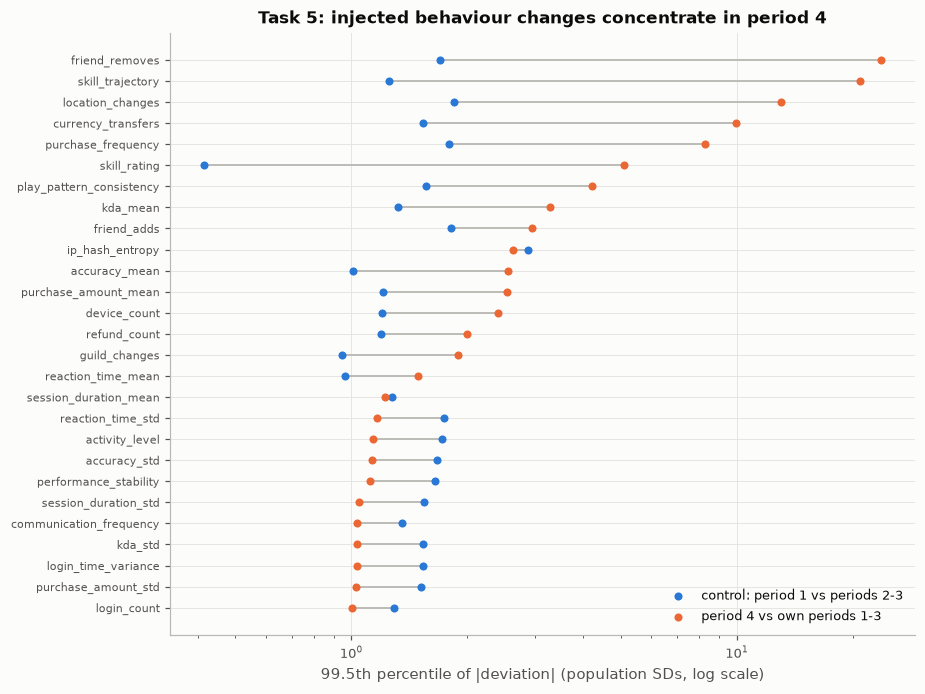

In [4]:
groups5 = [g for g in task5.temporal_groups(t5_test) if g not in ("login_lat", "login_lon")]
rows = []
for gname in groups5:
    v = t5_test[[f"{gname}_{i}" for i in range(1, 5)]].values.astype(float)
    sd = np.nanstd(v[:, :3])
    dev4 = np.abs(v[:, 3] - np.nanmean(v[:, :3], axis=1)) / sd      # period 4 vs own periods 1-3
    dev1 = np.abs(v[:, 0] - np.nanmean(v[:, 1:3], axis=1)) / sd      # control: period 1 vs periods 2-3
    rows.append([gname, np.nanpercentile(dev1, 99.5), np.nanpercentile(dev4, 99.5)])
tail = pd.DataFrame(rows, columns=["group", "control (period 1)", "period 4"]).sort_values("period 4")
fig, ax = plt.subplots(figsize=(8.5, 6.4))
ax.hlines(tail.group, tail["control (period 1)"], tail["period 4"], color=MUTED, lw=1.2)
ax.scatter(tail["control (period 1)"], tail.group, color=CAT[0], s=28, label="control: period 1 vs periods 2-3", zorder=3)
ax.scatter(tail["period 4"], tail.group, color=CAT[1], s=28, label="period 4 vs own periods 1-3", zorder=3)
ax.set_xscale("log"); ax.set_xlabel("99.5th percentile of |deviation| (population SDs, log scale)")
ax.set_title("Task 5: injected behaviour changes concentrate in period 4"); ax.legend(loc="lower right")
ax.tick_params(axis="y", labelsize=7.5)
plt.tight_layout(); savefig(fig, "t5_eda_tails"); plt.show()

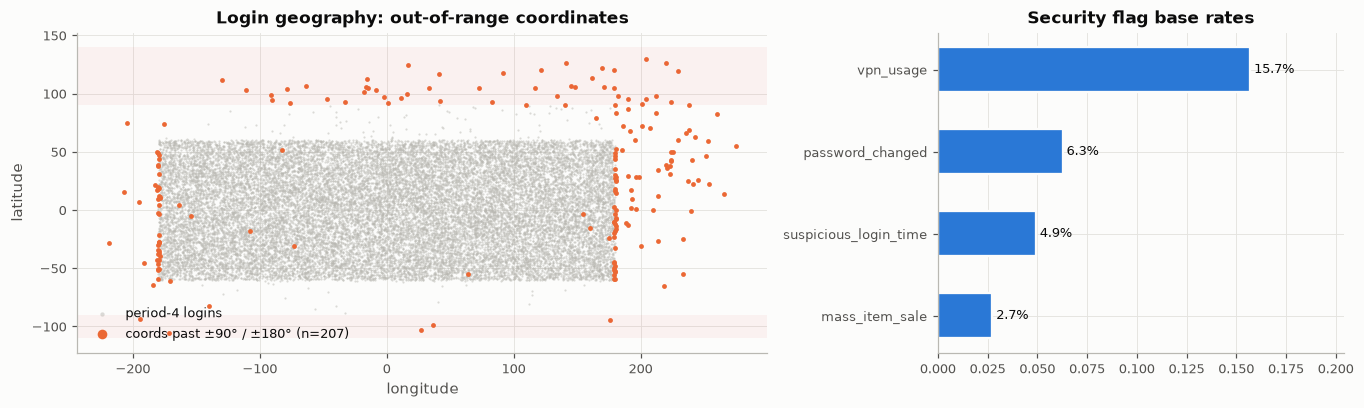

In [5]:
lat = t5_test[[f"login_lat_{i}" for i in range(1, 5)]]
lon = t5_test[[f"login_lon_{i}" for i in range(1, 5)]]
invalid = (lat.abs() > 90).any(axis=1) | (lon.abs() > 180).any(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), gridspec_kw={"width_ratios": [1.7, 1]})
axes[0].scatter(t5_test.login_lon_4, t5_test.login_lat_4, s=2, color=MUTED, alpha=0.5, label="period-4 logins")
axes[0].scatter(t5_test.login_lon_4[invalid], t5_test.login_lat_4[invalid], s=10, color=CAT[1], label=f"coords past ±90° / ±180° (n={invalid.sum()})")
axes[0].axhspan(90, 140, color=CAT[7], alpha=0.06); axes[0].axhspan(-110, -90, color=CAT[7], alpha=0.06)
axes[0].set_xlabel("longitude"); axes[0].set_ylabel("latitude"); axes[0].legend(loc="lower left", markerscale=2)
axes[0].set_title("Login geography: out-of-range coordinates")
flags = task5.FLAG_COLS
fr = t5_test[flags].mean().sort_values()
axes[1].barh(fr.index, fr.values, color=CAT[0], height=0.55, **viz.bar_gap())
for i, v in enumerate(fr.values):
    axes[1].text(v, i, f" {v:.1%}", va="center", fontsize=8.5)
axes[1].set_xlim(0, fr.max() * 1.3); axes[1].set_title("Security flag base rates")
plt.tight_layout(); savefig(fig, "t5_eda_geo"); plt.show()

**Findings.** For every behaviour, the deviation of **period 4 from the account's own periods 1–3** behaves like the control (period 1 vs 2–3) up to the ~98th percentile. Then it explodes for specific families:
* **Takeover / boosting:** `skill_rating`, `skill_trajectory`, `kda_mean`, `accuracy_mean` jump, `friend_removes` spikes and reaction time drops. These co-occur.
* **Credential theft / VPN abuse:** `location_changes`, `currency_transfers` and `purchase_*` spikes with long login jumps, plus a drop in `play_pattern_consistency`.
* **Out-of-range coordinates are not a rule on their own.** About two thirds belong to those teleporting accounts. The rest are players near the date line whose longitude wraps past ±180° with no actual travel. The geo signal is therefore the wrap-aware great-circle jump (haversine), not the coordinate range.

So one anomaly signature is a **change relative to the account's own baseline**, which drives the feature engineering below. §5.3 shows a second kind that never changes: accounts that are abnormal in *every* period (single-IP clockwork bots, near-zero activity or chat, very low `behavior_stability`).

<a id="4"></a>
# 4. Data Preparation & Feature Engineering

## 4.5 Task 5: impossible travel, self-referential deviations and burstiness
* **Geodesic features:** Haversine distance between consecutive login coordinates (1→2→3→4), max hop, total path, period-4 distance from the account's historical centroid, km per login in period 4, and an **invalid-coordinate flag** ($|lat|>90°$ or $|lon|>180°$).
* **Self-referential deviation (for each of the 27 behaviours):** `dev4` = (x₄ − mean(x₁..x₃)) / population SD, `selfz4`, the same scaled by the account's own variability, `maxjump`, the largest first difference, `burst`, max / mean, and `cv`, the dispersion over the 4 periods.
* Static attributes and the 4 security flags (plus their count).

In [6]:
X5, dev5 = task5.build_features(t5_test)
geo5 = [c for c in X5.columns if c.startswith("geo_")]
selfz5 = [c for c in X5.columns if c.endswith("_selfz4")]
dyn5 = [c for c in X5.columns if c.endswith(("_maxjump", "_burst", "_cv"))]
static5 = task5.STATIC_COLS + ["n_flags"]
print(f"Task 5 engineered matrix: {X5.shape} | dev4: {len(dev5)} | selfz4: {len(selfz5)} | dynamics: {len(dyn5)} | geo: {len(geo5)}")
display(X5[["geo_hop_34", "geo_p4_from_home_km", "geo_invalid_coord", "skill_rating_dev4", "friend_removes_dev4",
            "currency_transfers_dev4", "location_changes_dev4"]].describe(percentiles=[.5, .99, .999]).T.round(3))

Task 5 engineered matrix: (25889, 179) | dev4: 27 | selfz4: 27 | dynamics: 81 | geo: 9


,count,mean,std,min,50%,99%,99.9%,max
geo_hop_34,"21,126.0000",222.1370,989.1800,0.0000,85.3430,"6,862.7250","10,534.8990","12,666.0630"
geo_p4_from_home_km,"23,395.0000",199.3300,942.8120,0.1890,70.4060,"6,061.8390","10,532.0550","12,644.4940"
geo_invalid_coord,"25,889.0000",0.0080,0.0890,0.0000,0.0000,0.0000,1.0000,1.0000
skill_rating_dev4,"24,633.0000",0.0590,0.6030,-0.5520,0.0020,2.7670,8.4430,11.4730
friend_removes_dev4,"24,612.0000",0.2690,2.5100,-1.4810,0.0000,15.6250,30.0160,32.5340
currency_transfers_dev4,"24,670.0000",0.1160,1.1060,-1.4710,0.0010,6.6000,13.3700,16.0450
location_changes_dev4,"24,599.0000",0.2040,1.5870,-1.4550,0.0020,9.9990,17.6290,20.0030


<a id="5"></a>
# 5. Model Training & Evaluation

Task 5 has no labels, so there is no train/validation split. The detectors are fitted on the unlabeled accounts, and their agreement with the gap-separated families is the diagnostic.

In [7]:
from sklearn.metrics import roc_auc_score, confusion_matrix, f1_score
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer


def cached(name, fn, force=False):
    # Return {'oof','test',...} arrays, training via fn() only when no cache exists.
    r = load_preds(name)
    if r is None or force:
        t0 = time.time()
        out = fn()
        r = {k: np.asarray(v) for k, v in out.items() if k in ("oof", "test", "p_oof", "mu_oof", "p_test", "mu_test", "sigma", "smear", "n_iter")}
        save_preds(name, **r)
        print(f"  trained {name} in {time.time() - t0:.0f}s")
    return r

BASE = {"learning_rate": 0.05}
summary = []   # running scoreboard

### 5.3 Task 5: anomaly families and detector diagnostics (no labels)
Before scoring detectors, we ask how the anomalies are *distributed*. EDA showed that `behavior_stability` is uniform on 0.70–0.95 for 99% of accounts, while 274 accounts sit on 0.20–0.40 with **nothing in between**. A long tail does not leave an empty gap. A separate population of planted or anomalous behaviour does.

`task5.gap_clusters` turns this into a label-free detector that runs on every column. In each 10% tail it tests the widest empty gaps. With $d$ the density of the 200 accounts next to the gap and $w$ its width, $\lambda = d\,w$ is the number of accounts we would *expect* inside the gap if the bulk simply continued, and $P(\text{gap empty}) \approx e^{-\lambda}$. Accounts beyond a gap with $\lambda \ge 50$ form an **isolated tail cluster**. Groups under 20 accounts are individual outliers, not populations; this excludes, for example, longitudes that wrap past ±180° for players near the date line. Groups over 3% are zero-inflated counts. Clusters that share accounts are merged into **families** (union-find, overlap ≥ 50%). One family is one behaviour seen through several columns: a bot shows low IP entropy *and* clockwork login times *and* constant session lengths.

The result does not hinge on these settings. The flagged set is the identical 1,811 accounts for $\lambda \ge$ 50, 100 or 300, neighbourhoods of 100–400 accounts, tails of 5–15%, and minimum group sizes of 10–50. Only a much looser $\lambda \ge 20$ adds 40 borderline accounts.

The families then serve as a yardstick for the six statistical detectors: which behaviours does each one see in its top 7%?

group,size,share,gap_from,gap_to,expected_in_gap
friend_removes_4 > 12.54,301,1.16%,4.800,20.289,"47,932"
behavior_stability < 0.5497,274,1.06%,0.399,0.700,"29,692"
ip_hash_entropy_1 < 0.2497,202,0.78%,0.199,0.300,"5,610"
ip_hash_entropy_3 < 0.2491,195,0.75%,0.198,0.300,"5,164"
ip_hash_entropy_4 < 0.2489,200,0.77%,0.198,0.300,"5,066"
ip_hash_entropy_2 < 0.2486,197,0.76%,0.197,0.300,"4,848"
purchase_frequency_4 > 8.165,199,0.77%,5.997,10.333,"2,203"
geo_hop_max > 950.6,443,1.71%,366.100,1535.175,"2,076"
currency_transfers_4 > 15.99,299,1.15%,11.948,20.031,"2,047"
location_changes_4 > 4.326,479,1.85%,3.592,5.059,"1,140"


family,accounts,share,columns that isolate it
takeover / VPN abuse,517,2.00%,6
skill boost + friend purge,310,1.20%,2
erratic (low stability),274,1.06%,1
near-inactive,266,1.03%,4
silent (no chat),237,0.92%,4
single-IP bots,207,0.80%,14


31 isolated tail clusters -> 6 families -> 1,811 accounts (7.00%)
  ExtremeValue        0.1s


  IsolationForest     5.9s


  ECOD                3.8s


  COPOD               1.2s


  LOF                 3.1s


  Mahalanobis(MCD)   16.2s


  AutoEncoder        43.8s


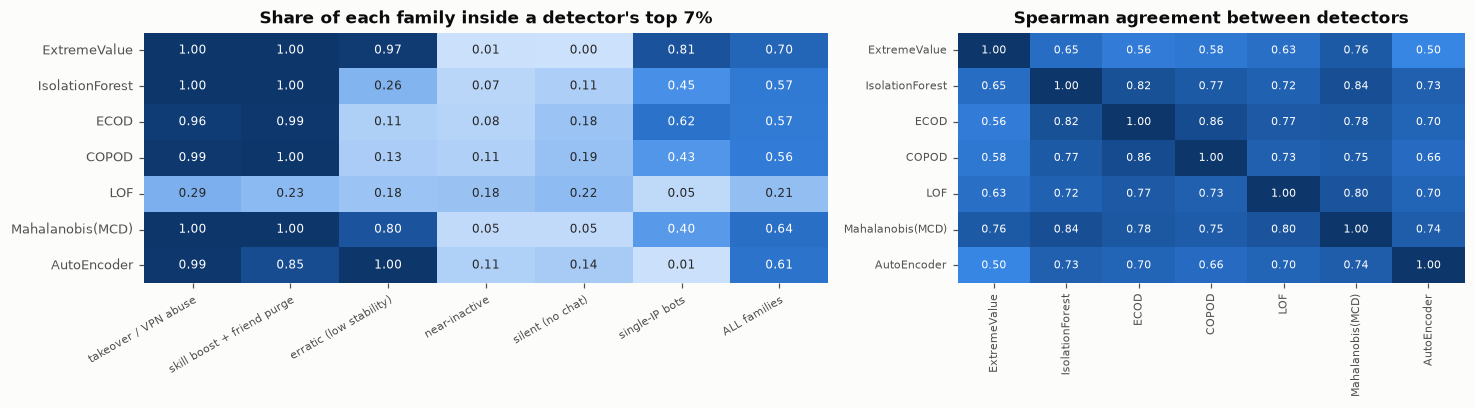

In [8]:
cols5 = task5.detector_columns(X5)
Z5 = task5.detector_matrix(X5, cols5, "robust")
gc_table, gc_masks = task5.gap_clusters(t5_test, X5)
gc_fams = task5.merge_families(gc_masks)
FAMILY_NAMES = {"friend_removes_4": "skill boost + friend purge", "behavior_stability": "erratic (low stability)",
                "location_changes_4": "takeover / VPN abuse", "activity_level": "near-inactive",
                "communication_frequency": "silent (no chat)", "ip_hash_entropy": "single-IP bots"}
def fam_name(groups):
    for g in groups:
        for key, nm in FAMILY_NAMES.items():
            if g.startswith(key):
                return nm
    return groups[0]
fam_mask = {fam_name(f): gc_masks[f].any(axis=1).values for f in sorted(gc_fams, key=lambda f: -gc_masks[f].any(axis=1).sum())}
gap5 = gc_masks.any(axis=1).values
display(gc_table[["group", "size", "share", "gap_from", "gap_to", "expected_in_gap"]].style.format(
    {"share": "{:.2%}", "gap_from": "{:.3f}", "gap_to": "{:.3f}", "expected_in_gap": "{:,.0f}"}).hide(axis="index"))
display(pd.DataFrame([[nm, int(m.sum()), m.mean(), len(f)] for (nm, m), f in zip(fam_mask.items(), sorted(gc_fams, key=lambda f: -gc_masks[f].any(axis=1).sum()))],
                     columns=["family", "accounts", "share", "columns that isolate it"]).style.format({"share": "{:.2%}"}).hide(axis="index"))
print(f"{len(gc_table)} isolated tail clusters -> {len(gc_fams)} families -> {gap5.sum():,} accounts ({gap5.mean():.2%})")

det_scores = {}
for name, fn in task5.DETECTORS.items():
    t0 = time.time()
    s = fn(Z5, device=DEVICE) if name == "AutoEncoder" else fn(Z5)
    det_scores[name] = task5.robust_z(s)
    print(f"  {name:17s} {time.time() - t0:5.1f}s")

BUDGET = 0.07
cov = pd.DataFrame({name: {**{k: (s >= np.quantile(s, 1 - BUDGET))[m].mean() for k, m in fam_mask.items()},
                           "ALL families": (s >= np.quantile(s, 1 - BUDGET))[gap5].mean()}
                    for name, s in det_scores.items()}).T
fig, axes = plt.subplots(1, 2, figsize=(13.5, 3.8), gridspec_kw={"width_ratios": [1.35, 1]})
sns.heatmap(cov, annot=True, fmt=".2f", cmap=SEQ_CMAP, vmin=0, vmax=1, ax=axes[0], cbar=False, annot_kws={"size": 8})
axes[0].set_title(f"Share of each family inside a detector's top {BUDGET:.0%}"); axes[0].tick_params(axis="x", rotation=30, labelsize=7.5)
plt.setp(axes[0].get_xticklabels(), ha="right", rotation_mode="anchor")
corr5 = pd.DataFrame(det_scores).corr("spearman")
sns.heatmap(corr5, annot=True, fmt=".2f", cmap=SEQ_CMAP, vmin=0, vmax=1, ax=axes[1], cbar=False, annot_kws={"size": 7.5})
axes[1].set_title("Spearman agreement between detectors"); axes[1].tick_params(labelsize=7.5)
plt.tight_layout(); savefig(fig, "t5_detectors"); plt.show()

**Reading the diagnostics.** Six families account for 7.0% of accounts. Each is cut off from normal behaviour by a gap that should hold hundreds to tens of thousands of accounts if it were just a tail.

* **Every detector except LOF sees the spike families.** Teleports, transfers and purchase spikes (takeover / VPN abuse), and skill jumps with friend purges, land in the top 7% for 96–100% of their accounts.
* **Coverage of the "too low" families depends on the gap's distance from the bulk.** Very low `behavior_stability` and single-IP bots sit 5–6 robust SDs (1.4826·MAD) below the median. The extreme-value detector, autoencoder and MCD catch the low-stability family (0.97 / 1.00 / 0.80). Bots are caught mostly by the extreme-value detector (0.81).
* **Near-inactive and silent accounts are invisible to all of them (≤ 0.22).** Their activity and chat levels sit only about 2 robust SDs below the median. In 70 dimensions they are swamped by accounts that are merely noisy, the classic weakness of distance and density scores on bounded features. Yet their gaps are unmistakable: zero accounts where hundreds are expected.
* **LOF covers little of anything (≤ 0.29).** Local density ratios in 70 dimensions mostly react to noise.

The gap-cluster detector therefore finds what the statistical detectors miss. The final decision (§7.5) still keeps the score ensemble and the hard-evidence rules alongside it, because under $F_3$ a missed anomaly costs far more than a false alarm.

<a id="6"></a>
# 6. Hyperparameter Tuning

Task 5 has no labels, so there is no objective to tune against. Instead, §5 shows that the gap detector's output does not depend on its settings: the identical 1,811 accounts are flagged for λ ≥ 50, 100 or 300, neighbourhoods of 100–400 accounts, tails of 5–15% and minimum group sizes of 10–50.

<a id="7"></a>
# 7. Stacking Ensemble (K-Fold) & Final Decision

The unsupervised evidence (gap families, score ensemble, hard-evidence rules) is combined into one decision chosen for the $F_3$ metric.

## 7.5 Task 5: Final decision (the F3-robust union of three lines of evidence)
1. **Score ensemble.** Each retained detector's raw score is robust-z standardised (median/MAD) and the results are averaged (LOF excluded, §5.3). The knee (Kneedle) of the sorted log-excess marks where scores stop falling steeply.
2. **Isolated tail clusters (§5.3).** Every account in a gap-separated family is flagged. Their membership needs no threshold choice: the gap *is* the threshold, and it is set by the data.
3. **F3 asymmetry.** For a perfect ranker with true rate $r$ that flags a fraction $q$, $F_3(q) = \frac{10\,\min(q,r)/q}{9\,\min(q,r)/q + \min(q,r)/r}$. Missing anomalies is about 9× costlier than a false alarm, so a whole family the score ensemble cannot see (near-inactive, silent accounts) has to be caught by the family detector.
4. **Ensemble alerts outside the families.** They are inspected below. Their largest robust z is modest, and they are enriched for the four yes/no flags only because the ensemble reads those flags as inputs. Outside the families the flags are statistically independent: the number of accounts with 0, 1, 2 or 3 flags matches the independence prediction almost exactly. So *statistically* they look like the noisy edge of normal behaviour.
5. **But the labels are not ours to see.** Task 5 has no labels, and we cannot know whether the organisers' anomaly definition is the gap families, the multivariate outliers the score ensemble finds, or the hard-evidence rules (period-4 values outside the account's own history, impossible coordinates, the two bimodal gaps). The metric settles the decision. $F_3$ weighs recall 9× more than precision, and the Bayes-optimal $F_\beta$ decision flags every account whose anomaly probability exceeds $F^*/(1+\beta^2) \approx F^*/10$ (Lipton et al., 2014). An account that an independent line of evidence flags is far more likely than ~10% to be an anomaly under at least one plausible definition. We therefore flag the **union** of the three. The table below scores each candidate rule as if each of the others were the truth: the union is never far from the best, while committing to a single definition can lose about a quarter of the score.

,ExtremeValue,IsolationForest,ECOD,COPOD,LOF,Mahalanobis(MCD),AutoEncoder
LOO-consensus Spearman,0.6997,0.8691,0.8530,0.8239,0.8353,0.9145,0.7567
in fusion,True,True,True,True,False,True,True


score-ensemble knee: top 6.25% | families: 7.00% | ensemble ROC-AUC for family membership: 0.9160


,accounts,caught by ensemble knee
takeover / VPN abuse,517,100.0%
skill boost + friend purge,310,100.0%
erratic (low stability),274,75.9%
near-inactive,266,3.8%
silent (no chat),237,7.6%
single-IP bots,207,40.1%


ensemble-only alerts: 473 | median of their largest |robust z|: 1.83 (families 2.88, unflagged accounts 1.01)
binary-flag rates (password / vpn / odd-hour / mass-sale): {'ensemble-only': [0.2980000078678131, 0.2849999964237213, 0.2849999964237213, 0.09300000220537186], 'unflagged': [0.04699999839067459, 0.14800000190734863, 0.04500000178813934, 0.017999999225139618]}


flags set,0,1,2,3,4
accounts observed,"14,787.0000","4,485.0000",397.0000,15.0000,0.0000
expected if independent,"14,790.3000","4,477.4000",402.4000,13.7000,0.1000


,accounts flagged,truth = gap families,truth = ensemble knee + evidence rules,truth = families ∩ (knee + rules),worst case
gap families,1811,1.000,0.737,0.965,0.737
ensemble knee + evidence rules,1802,0.734,1.000,0.966,0.734
union of all three,2285,0.974,0.974,0.933,0.933


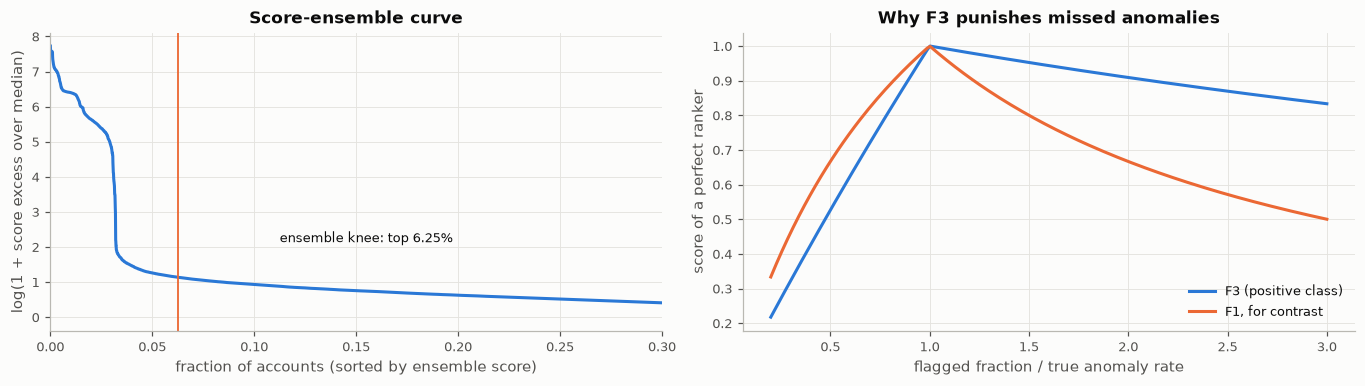

FINAL Task 5 flags: 2,285 = 8.83% of accounts (families 1,811 + 474 from the score ensemble / evidence rules)


In [9]:
members = [k for k in det_scores if k != "LOF"]
M5 = np.column_stack([det_scores[k] for k in members])
w_sel, agree = task5.consensus_weights(np.column_stack(list(det_scores.values())))
display(pd.DataFrame({"LOO-consensus Spearman": agree, "in fusion": [k in members for k in det_scores]}, index=list(det_scores)).T)
consensus = M5.mean(axis=1)
s_sorted = np.sort(consensus)[::-1]
log_excess = np.log1p(np.clip(s_sorted - np.median(s_sorted), 0, None))
knee = task5.knee_point(log_excess)
Q5 = knee / len(consensus)
flag_ml = consensus >= s_sorted[knee]
print(f"score-ensemble knee: top {Q5:.2%} | families: {gap5.mean():.2%} | ensemble ROC-AUC for family membership: {roc_auc_score(gap5, consensus):.4f}")
rec = pd.DataFrame({"accounts": {k: int(m.sum()) for k, m in fam_mask.items()},
                    "caught by ensemble knee": {k: flag_ml[m].mean() for k, m in fam_mask.items()}})
display(rec.style.format({"caught by ensemble knee": "{:.1%}"}))

# ensemble-only alerts: do they look like a population, or like the noisy edge of normal behaviour?
extra = flag_ml & ~gap5
normal = ~flag_ml & ~gap5
zdf = pd.DataFrame(Z5, columns=cols5)
top_abs = zdf.abs().max(axis=1)
print(f"ensemble-only alerts: {extra.sum():,} | median of their largest |robust z|: {np.median(top_abs[extra]):.2f} "
      f"(families {np.median(top_abs[gap5]):.2f}, unflagged accounts {np.median(top_abs[normal]):.2f})")
print("binary-flag rates (password / vpn / odd-hour / mass-sale):",
      {nm: np.round(t5_test.loc[m, task5.FLAG_COLS].mean().values, 3).tolist() for nm, m in [("ensemble-only", extra), ("unflagged", normal)]})
# The ensemble reads the four flags as inputs, so ensemble-only alerts are enriched for flags by construction.
# Is "several flags at once" a population of its own? Outside the families, compare the number of flags
# per account with what independent flags would produce (Poisson-binomial).
Fl = t5_test.loc[~gap5, task5.FLAG_COLS].dropna()
pr = Fl.mean().values
expd = np.array([1.0])
for r in pr:
    expd = np.convolve(expd, [1 - r, r])
nflag = Fl.sum(axis=1).astype(int).value_counts().reindex(range(5), fill_value=0)
display(pd.DataFrame({"accounts observed": nflag.values, "expected if independent": np.round(expd * len(Fl), 1)},
                     index=pd.Index(range(5), name="flags set")).T)

# F3-robust decision: score each candidate rule as if each candidate were the ground truth
rules5 = task5.evidence_rules(t5_test)
rule5 = rules5.any(axis=1).values
cands5 = {"gap families": gap5, "ensemble knee + evidence rules": flag_ml | rule5, "union of all three": gap5 | flag_ml | rule5}
truths5 = {"gap families": gap5, "ensemble knee + evidence rules": flag_ml | rule5, "families ∩ (knee + rules)": gap5 & (flag_ml | rule5)}
rob5 = pd.DataFrame({f"truth = {tn}": {dn: f3(t.astype(int), d.astype(int)) for dn, d in cands5.items()} for tn, t in truths5.items()})
rob5["worst case"] = rob5.min(axis=1)
rob5.insert(0, "accounts flagged", [int(d.sum()) for d in cands5.values()])
display(rob5.style.format({c: "{:.3f}" for c in rob5.columns if c != "accounts flagged"}).highlight_max(subset=["worst case"], props="font-weight:bold"))
flag5 = cands5["union of all three"]
pred5 = flag5.astype(int)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6))
ranks = np.arange(1, len(s_sorted) + 1) / len(s_sorted)
axes[0].plot(ranks, log_excess, color=CAT[0], label="all accounts")
axes[0].axvline(Q5, color=CAT[1], lw=1.2)
axes[0].annotate(f"ensemble knee: top {Q5:.2%}", (Q5, log_excess[knee]), xytext=(Q5 + 0.05, log_excess[knee] + 1.0), fontsize=8.5,
                 arrowprops=dict(arrowstyle="-", color=MUTED))
axes[0].set_xlim(0, 0.3); axes[0].set_xlabel("fraction of accounts (sorted by ensemble score)")
axes[0].set_ylabel("log(1 + score excess over median)"); axes[0].set_title("Score-ensemble curve")
r_true = gap5.mean()
qs = np.linspace(0.2, 3, 200) * r_true
axes[1].plot(qs / r_true, task5.expected_fbeta(qs, r_true, 3), color=CAT[0], label="F3 (positive class)")
axes[1].plot(qs / r_true, task5.expected_fbeta(qs, r_true, 1), color=CAT[1], label="F1, for contrast")
axes[1].set_xlabel("flagged fraction / true anomaly rate"); axes[1].set_ylabel("score of a perfect ranker")
axes[1].set_title("Why F3 punishes missed anomalies"); axes[1].legend(loc="lower right")
plt.tight_layout(); savefig(fig, "t5_threshold"); plt.show()
print(f"FINAL Task 5 flags: {pred5.sum():,} = {pred5.mean():.2%} of accounts "
      f"(families {gap5.sum():,} + {int((flag5 & ~gap5).sum()):,} from the score ensemble / evidence rules)")
AGREE5 = rob5.loc["union of all three", "worst case"]
summary.append(["Task 5", "worst-case F3 over 3 anomaly definitions", AGREE5,
                "union: 6 gap families (1-D density-gap detector) + 6-detector ensemble knee + hard-evidence rules"])

<a id="8"></a>
# 8. Feature Importance Analysis

Every alert is explained by the behaviour that isolates it (the family's gap column), or by the evidence rule or score ensemble that raised it.

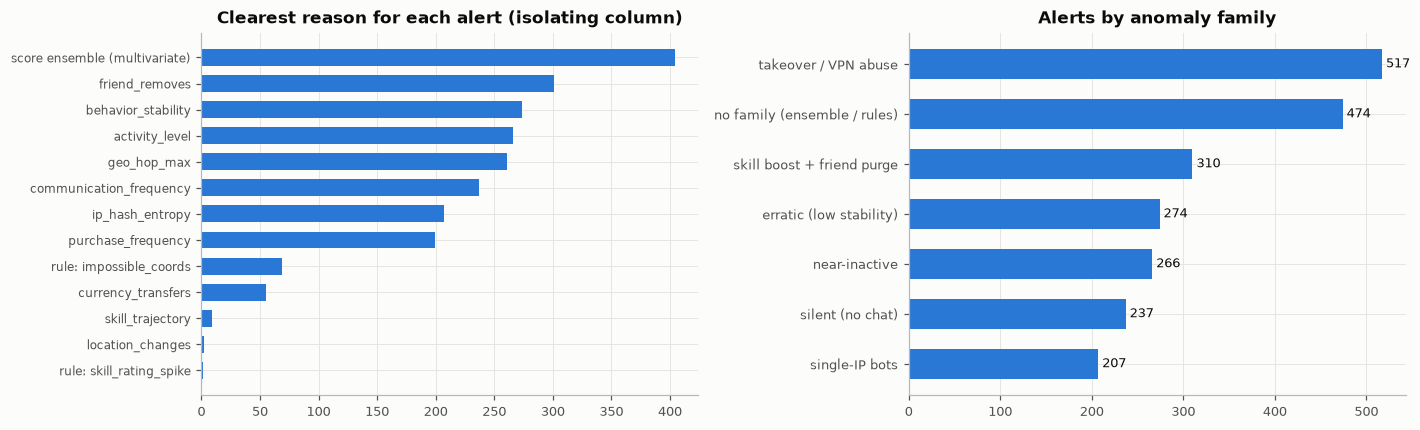

In [10]:
flagged = np.where(pred5 == 1)[0]
# reason = the column that isolates the account most clearly (largest expected-in-gap among its clusters)
order = gc_table.group.tolist()
G = gc_masks[order].values[flagged]
R5 = rules5.values[flagged]
reason = pd.Series([gc_table.column[int(np.argmax(g))] if g.any() else
                    (f"rule: {rules5.columns[int(np.argmax(r))]}" if r.any() else "score ensemble (multivariate)")
                    for g, r in zip(G, R5)]).str.replace(r"_[1-4]$", "", regex=True)
drv = reason.value_counts().head(14).sort_values()
fam_counts = pd.Series({**{k: int((m & (pred5 == 1)).sum()) for k, m in fam_mask.items()},
                        "no family (ensemble / rules)": int((flag5 & ~gap5).sum())}).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].barh(drv.index, drv.values, color=CAT[0], height=0.65); axes[0].set_title("Clearest reason for each alert (isolating column)")
axes[0].tick_params(axis="y", labelsize=8)
axes[1].barh(fam_counts.index, fam_counts.values, color=CAT[0], height=0.6)
for i, v in enumerate(fam_counts.values):
    axes[1].text(v, i, f" {v}", va="center", fontsize=8.5)
axes[1].set_title("Alerts by anomaly family"); axes[1].tick_params(axis="y", labelsize=8.5)
plt.tight_layout(); savefig(fig, "t5_drivers"); plt.show()

**Business reading (security).** Every alert comes with a family and the behaviour that isolates it, so the security team can route each one:
* **Takeover / VPN abuse** (teleporting logins with a currency drain, or with a purchase spike behind a VPN): freeze outgoing transfers, force a password reset, add step-up authentication, and re-price VPN purchases.
* **Skill boost + friend purge** (sudden skill jump in the last period, friends removed): account sharing or selling. Review, and notify the owner.
* **Bots** (one IP, clockwork login times, constant session length, flat KDA): rate-limit, then batch-ban by IP.
* **Silent and near-inactive accounts** (no chat at all, or barely active in every period): farm and mule accounts. Watch for transfers into them.
* **Erratic behaviour** (stability far below any normal player): resellers and shared accounts. Review.
* **No family (ensemble or rule only):** the lowest-priority queue. These accounts are flagged because missing an anomaly costs far more than a review, but they are statistically closest to normal players.

The current rule system has a 60% false-positive rate and treats every alert the same way. Typed, explained alerts let a small team triage efficiently. The family detector also needs no hand-set threshold: each gap in the data defines its own cut-off, so it adapts when behaviour drifts.

<a id="9"></a>
# 9. Submission

The Task 5 column of the submission: `task5` is a plain integer code, as defined in the datacard. The part is written to `outputs/submission_parts/task5.csv` with the `id` column of `sample_submission.csv`; `python scripts/make_submission.py` checks and joins the five parts.

In [11]:
sample_sub = pd.read_csv(C.SAMPLE_SUB)
part = pd.DataFrame({"id": sample_sub.id, "task5": pred5.astype(int)})
assert len(part) == C.N_TEST == len(t5_test) and part.id.tolist() == [f"ANS{i:05d}" for i in range(1, C.N_TEST + 1)]
assert part["task5"].notna().all() and set(part.task5.unique()) <= {0, 1}
part_dir = C.OUT / "submission_parts"
part_dir.mkdir(exist_ok=True)
part.to_csv(part_dir / "task5.csv", index=False)
print(f"saved {part_dir / 'task5.csv'} | {part.shape}")
display(part.head())
print(f"flagged accounts: {part.task5.sum():,} ({part.task5.mean():.2%})")

saved C:\Users\Oping\cpe342-kaggle-main\outputs\submission_parts\task5.csv | (25889, 2)


,id,task5
0,ANS00001,0
1,ANS00002,0
2,ANS00003,0
3,ANS00004,0
4,ANS00005,0


flagged accounts: 2,285 (8.83%)


<a id="10"></a>
# 10. Conclusion

In [12]:
display(pd.DataFrame(summary, columns=["task", "metric", "OOF score", "final recipe"]).set_index("task").style.format({"OOF score": "{:.4f}"}))

,metric,OOF score,final recipe
task,,,
Task 5,worst-case F3 over 3 anomaly definitions,0.9328,union: 6 gap families (1-D density-gap detector) + 6-detector ensemble knee + hard-evidence rules


| Task | Key insight | What moved the score |
|---|---|---|
| 5 Security | Anomalies are **separate populations**: each family sits beyond an empty gap in some behaviour | **1-D density-gap detector** (expected-in-gap statistic) finds 6 families with no hand-set threshold; under $F_3$ the **union** with the score-ensemble knee and the hard-evidence rules is the robust decision |